# 03 · The day-ahead forecast and how accurate it is

**Purpose.** Train-free walkthrough of the production model and its honest evaluation on the untouched 2026 year.

```
 feature table ─► 3-seed LightGBM ensemble (PV as clear-sky index) ─► P50
               └► quantile LightGBMs ─► conformal widening (held-out 2025 days) ─► 80 % / 95 % bands
```
CQR: with raw band $[q_{lo}, q_{hi}]$, conformity score $E = \max(q_{lo}-y,\ y-q_{hi})$ on the calibration set; the band is widened by
its $(1-\alpha)(1+1/n)$ quantile, which guarantees the stated coverage on exchangeable new data.

**Key takeaways**
1. Hourly PV and total power are explained to R² ≈ 0.97; capacity accuracy ≥ 95 %.
2. Calibrated 95 % intervals cover ~95 % of the test hours.
3. Daily energy and wind are below 95 %: the oracle ceiling shows why.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from aerosolar.config import Config, REPO_ROOT
from aerosolar.sim.realism import _style, S1, S2, S3, INK, INK2
_style(); plt.rcParams['figure.dpi'] = 110
cfg = Config.load()
DATA = REPO_ROOT / 'data'
pd.set_option('display.width', 140); pd.set_option('display.max_columns', 30)
from aerosolar.ml.train import load_latest, load_split
bundle, meta = load_latest()
print('model version', meta['version'])

model version 20261001T125452Z


In [2]:
import json
from aerosolar.ml.evaluate import headline
m = json.loads((REPO_ROOT / 'reports' / 'forecast_metrics.json').read_text())
pd.DataFrame([(a, b, f'{100 * c:.1f} %', 'yes' if ok else 'no') for a, b, c, ok in headline(m)],
             columns=['statistic', 'definition', 'value (2026 test year)', '≥ 95 %'])

,statistic,definition,value (2026 test year),≥ 95 %
0,"R², total power (day-ahead)","explained variance, hourly total",96.8 %,yes
1,"R², PV power (day-ahead)","explained variance, hourly PV",97.2 %,yes
2,"R², PV potential (day-ahead)","same, hours without curtailment",97.8 %,yes
3,"R², total potential (day-ahead)","same, total",97.1 %,yes
4,"Capacity accuracy, total (day-ahead)",1 − RMSE / 30 W,96.5 %,yes
5,"Capacity accuracy, total potential (day-ahead)","1 − RMSE / 30 W, no curtailment",96.7 %,yes
6,"Capacity accuracy, PV potential (day-ahead)","1 − RMSE / 18 W, no curtailment",95.2 %,yes
7,"95 % interval coverage, total (day-ahead)",share of actuals inside the 95 % band,95.1 %,yes
8,"95 % interval coverage, PV (day-ahead)","same, PV",97.1 %,yes
9,"R², PV (rolling 1–24 h)",every hourly issue,97.2 %,yes


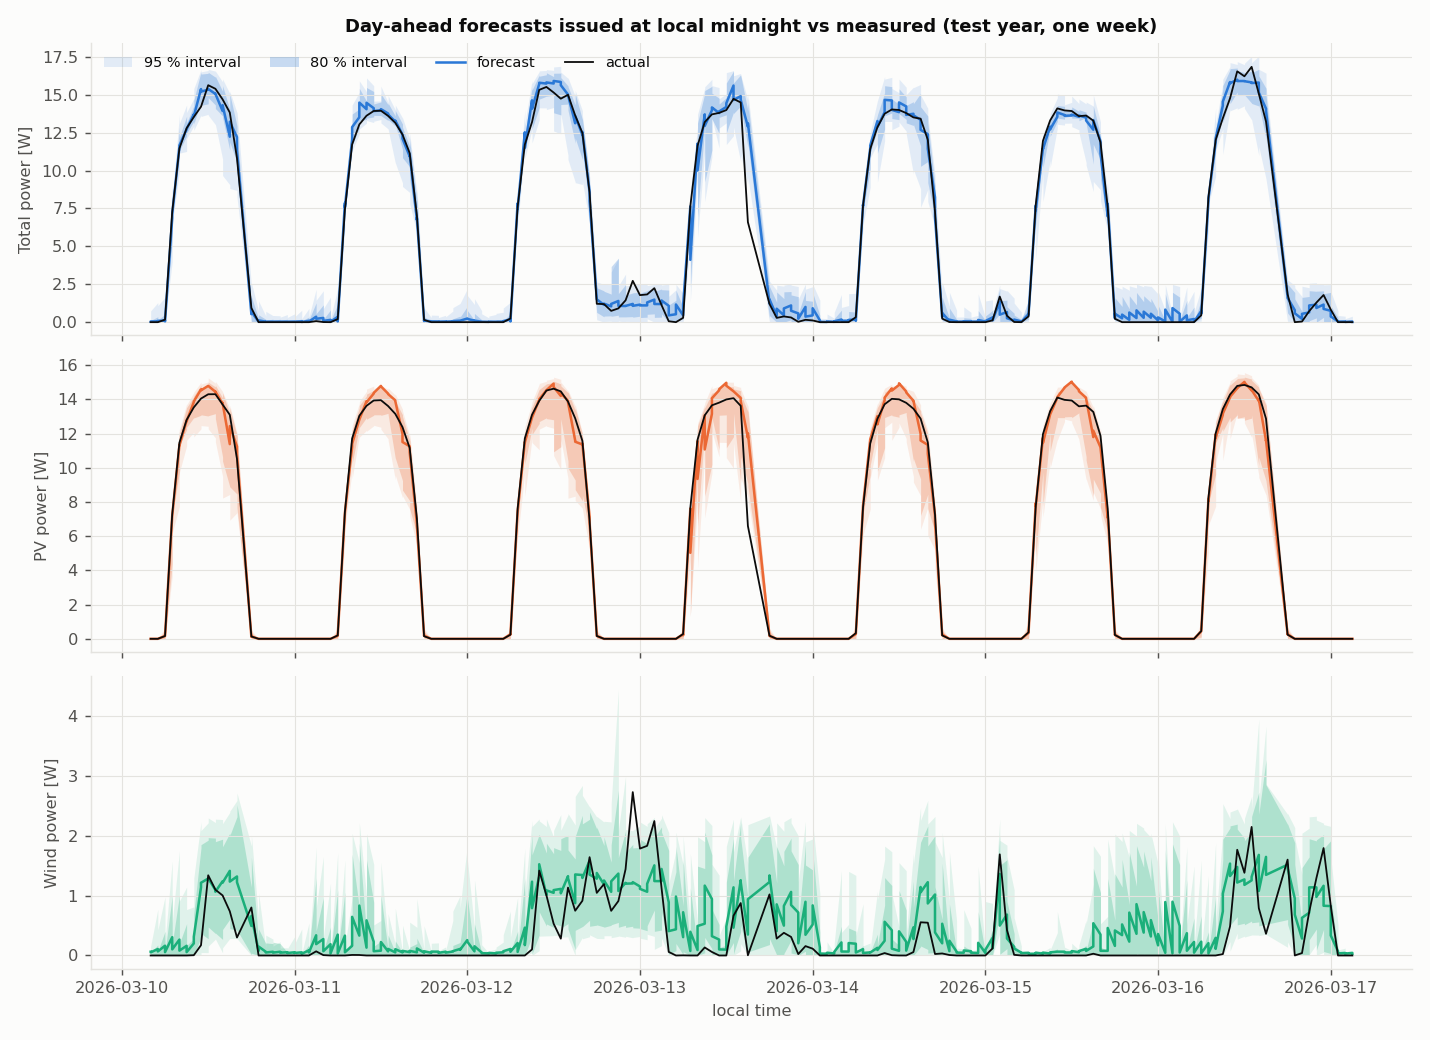

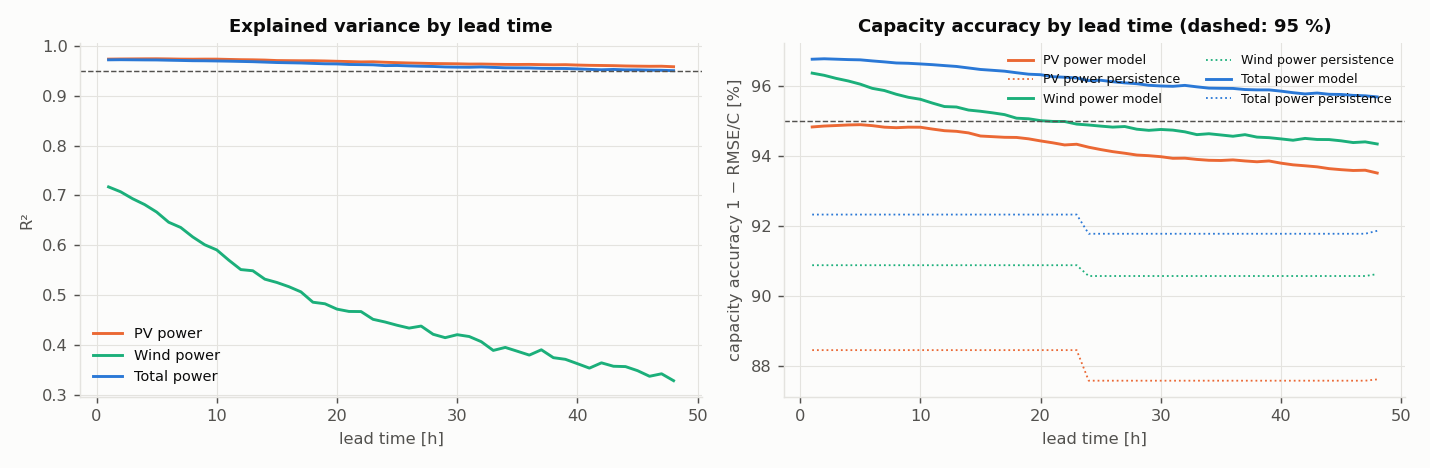

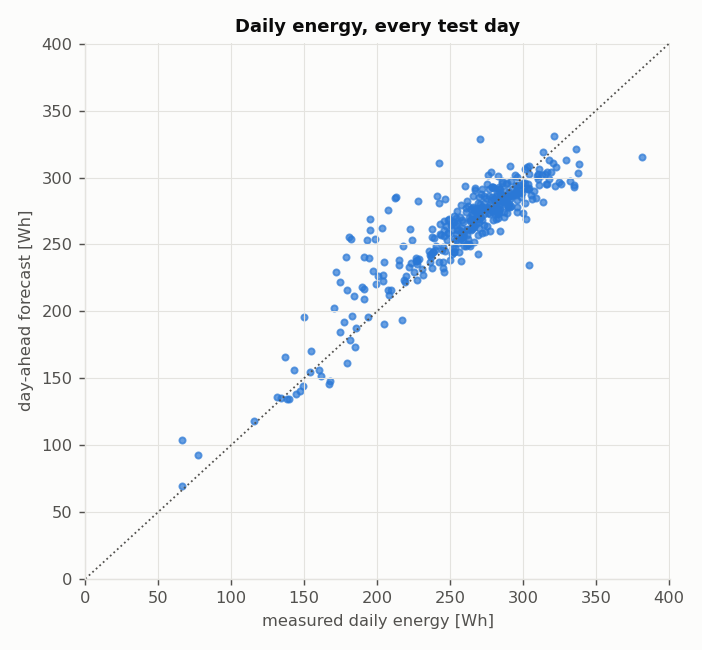

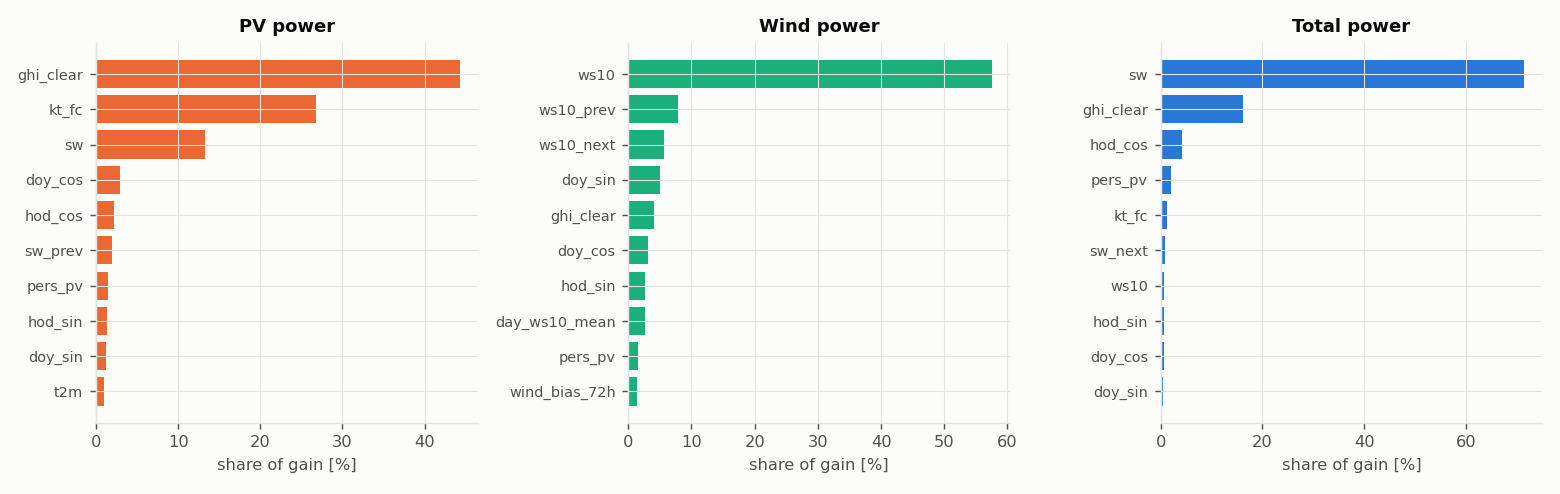

In [3]:
from IPython.display import Image, display
for f in ('week.png', 'by_lead.png', 'daily_energy.png', 'importance.png'):
    display(Image(filename=str(REPO_ROOT / 'reports' / 'forecast' / f)))

**What to notice.**
* The week plot: forecasts follow the daily solar cycle and cloudy/dusty days; actual wind power is spiky and the band is wide there.
* Accuracy by lead: the first hours benefit from the latest observations, then accuracy settles.
* Daily energy: points hug the diagonal; the misses are days with large irradiance-forecast errors.
* The model relies most on forecast irradiance, clear-sky geometry and recent PV yield (soiling).

In [4]:
o = m['oracle']; da = m['day_ahead']
pd.DataFrame({'forecast model': [da['pv']['r2'], da['pv']['daily_energy_accuracy_mean'], da['total']['daily_energy_accuracy_mean']],
              'oracle (true weather)': [o['pv']['r2'], o['pv']['daily_energy_accuracy_mean'], o['total']['daily_energy_accuracy_mean']]},
             index=['PV R²', 'PV daily energy accuracy', 'total daily energy accuracy']).round(3)

,forecast model,oracle (true weather)
PV R²,0.972,0.979
PV daily energy accuracy,0.927,0.950
total daily energy accuracy,0.942,0.956


**What to notice.** Even a model that knows the true weather cannot get far above 95 % daily energy accuracy here: soiling,
tracker error and curtailment are not in the weather. The remaining gap is the day-ahead forecast error itself.

> **Caution.** All numbers are from simulated data with assumed forecast errors. Real accuracy is known only after weeks
> of real data (notebook 05).

## What we learned
* Gradient boosting with physically meaningful features (clear-sky index, curtailment context, soiling tracker) reaches the
  information limit for PV; wind remains limited by weather predictability.

## References
* Romano, Patterson, Candès (2019). *Conformalized quantile regression.* NeurIPS.
* Ke et al. (2017). *LightGBM: a highly efficient gradient boosting decision tree.* NeurIPS.
* Yang et al. (2020). *Verification of deterministic solar forecasts.* Solar Energy 210 (clear-sky index, smart persistence, skill scores).
* Hong et al. (2016). *Probabilistic energy forecasting: GEFCom2014 and beyond.* IJF 32.
* Haurwitz (1945). *Insolation in relation to cloudiness and cloud density.* J. Meteorology.
* Kamoji, Kedare, Prabhu (2009). *Performance tests on helical Savonius rotors.* Renewable Energy 34.